# CSC2042S Assignment 1: Perceptron Image Classification
Student number: RHMABD006

This notebook implements a multi-class perceptron for image classification on the Simpsons-MNIST dataset. The dataset contains images of 10 Simpsons characters in RGB and grayscale formats. Models are trained with a one-vs-rest design, tuned on a validation split, and evaluated on a held-out test set. RGB and grayscale performance are compared, and a small data-augmentation study is reported.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from data_utils import (
    load_dataset,
    train_val_split,
    flatten_images,
    normalise
)
from perceptron import BinaryPerceptron, MultiClassPerceptron
from train_eval import train_model, evaluate_model, grid_search


## Task 1: Data Processing

The Simpsons-MNIST dataset contains images of 10 Simpsons characters in RGB and grayscale formats. The provided training data is divided into training and validation subsets, while the separate test set is kept untouched until final evaluation.

Each image is flattened into a one-dimensional feature vector so that it can be used as input to the perceptron.


In [2]:
X_rgb, y_rgb = load_dataset("DATA/rgb-train/train", mode="RGB")
X_gray, y_gray = load_dataset("DATA/train", mode="L")

print("RGB shape:", X_rgb.shape)
print("Grayscale shape:", X_gray.shape)
print("Labels shape:", y_rgb.shape)


RGB shape: (8000, 28, 28, 3)
Grayscale shape: (8000, 28, 28)
Labels shape: (8000,)


In [3]:

X_rgb_test, y_rgb_test = load_dataset("DATA/test", mode="RGB")
X_gray_test, y_gray_test = load_dataset("DATA/grayscale-test/test", mode="L")

X_rgb_test_flat = X_rgb_test.reshape(len(X_rgb_test), -1)
X_gray_test_flat = X_gray_test.reshape(len(X_gray_test), -1)

print("RGB test:", X_rgb_test_flat.shape)
print("Grayscale test:", X_gray_test_flat.shape)


RGB test: (2000, 2352)
Grayscale test: (2000, 784)


In [4]:
X_rgb_flat = X_rgb.reshape(X_rgb.shape[0], -1)
X_gray_flat = X_gray.reshape(X_gray.shape[0], -1)

print("Flattened RGB shape:", X_rgb_flat.shape)
print("Flattened grayscale shape:", X_gray_flat.shape)


Flattened RGB shape: (8000, 2352)
Flattened grayscale shape: (8000, 784)


### Train/validation split

The provided training set contains 8,000 images. I use 80% for model training and 20% for validation. A fixed random seed is used to make the split reproducible.

The separate test set is not used during model development or hyperparameter tuning.


In [5]:
X_rgb_train, y_rgb_train, X_rgb_val, y_rgb_val = train_val_split(
    X_rgb,
    y_rgb,
    val_fraction=0.2,
    random_state=42
)

X_gray_train, y_gray_train, X_gray_val, y_gray_val = train_val_split(
    X_gray,
    y_gray,
    val_fraction=0.2,
    random_state=42
)

print("RGB training:", X_rgb_train.shape, y_rgb_train.shape)
print("RGB validation:", X_rgb_val.shape, y_rgb_val.shape)

print("Grayscale training:", X_gray_train.shape, y_gray_train.shape)
print("Grayscale validation:", X_gray_val.shape, y_gray_val.shape)


RGB training: (6400, 28, 28, 3) (6400,)
RGB validation: (1600, 28, 28, 3) (1600,)
Grayscale training: (6400, 28, 28) (6400,)
Grayscale validation: (1600, 28, 28) (1600,)


In [6]:
X_rgb_train_flat = X_rgb_train.reshape(X_rgb_train.shape[0], -1)
X_rgb_val_flat = X_rgb_val.reshape(X_rgb_val.shape[0], -1)

X_gray_train_flat = X_gray_train.reshape(X_gray_train.shape[0], -1)
X_gray_val_flat = X_gray_val.reshape(X_gray_val.shape[0], -1)

print("RGB flattened training:", X_rgb_train_flat.shape)
print("RGB flattened validation:", X_rgb_val_flat.shape)

print("Grayscale flattened training:", X_gray_train_flat.shape)
print("Grayscale flattened validation:", X_gray_val_flat.shape)


RGB flattened training: (6400, 2352)
RGB flattened validation: (1600, 2352)
Grayscale flattened training: (6400, 784)
Grayscale flattened validation: (1600, 784)


## Task 2: Multi-class Perceptron

The classifier uses an object-oriented one-vs-rest design.

A `BinaryPerceptron` is created for each of the 10 Simpsons characters. Each binary perceptron learns to distinguish one class from all other classes.

The binary perceptrons initialise all weights and the bias to 0.1. For multiclass prediction, the raw score from each binary perceptron is calculated and the class with the highest score is selected.

In [7]:
from perceptron import BinaryPerceptron, MultiClassPerceptron


binary_model = BinaryPerceptron(
    n_features=784,
    learning_rate=0.01
)

print("Binary weight shape:", binary_model.weights.shape)
print("Binary weight minimum:", binary_model.weights.min())
print("Binary weight maximum:", binary_model.weights.max())
print("Binary bias:", binary_model.bias)


multiclass_model = MultiClassPerceptron(
    n_features=784,
    n_classes=10,
    learning_rate=0.01
)

print("Number of binary perceptrons:", len(multiclass_model.perceptrons))
print("Multiclass weight shape:", multiclass_model.weights.shape)
print("Multiclass weight minimum:", multiclass_model.weights.min())
print("Multiclass weight maximum:", multiclass_model.weights.max())


Binary weight shape: (784,)
Binary weight minimum: 0.1
Binary weight maximum: 0.1
Binary bias: 0.1
Number of binary perceptrons: 10
Multiclass weight shape: (10, 784)
Multiclass weight minimum: 0.1
Multiclass weight maximum: 0.1


In [8]:
X_toy = np.array([
    [1, 1],
    [2, 1],
    [1, 2],
    [8, 8],
    [9, 8],
    [8, 9]
])

y_toy = np.array([0, 0, 0, 1, 1, 1])

toy_model = BinaryPerceptron(
    n_features=2,
    learning_rate=0.1
)

print("Predictions before training:")
print(toy_model.predict(X_toy))


for epoch in range(10):
    mistakes = toy_model.train(X_toy, y_toy)

print("Predictions after training:")
print(toy_model.predict(X_toy))

print("True labels:")
print(y_toy)


Predictions before training:
[1 1 1 1 1 1]
Predictions after training:
[0 0 0 1 1 1]
True labels:
[0 0 0 1 1 1]


In [9]:
small_model = MultiClassPerceptron(
    n_features=784,
    n_classes=10,
    learning_rate=0.01
)


X_small = X_gray_train_flat[:200]
y_small = y_gray_train[:200]

small_model.train_epoch(
    X_small,
    y_small,
    rng=np.random.default_rng(42)
)


for class_id in range(10):
    predictions = small_model.perceptrons[class_id].predict(X_small)

    own_class_rate = predictions[y_small == class_id].mean()
    other_class_rate = predictions[y_small != class_id].mean()

    print(
        f"Class {class_id}: "
        f"own class = {own_class_rate:.3f}, "
        f"other classes = {other_class_rate:.3f}"
    )


Class 0: own class = 0.200, other classes = 0.011
Class 1: own class = 0.000, other classes = 0.000
Class 2: own class = 0.783, other classes = 0.333
Class 3: own class = 0.000, other classes = 0.000
Class 4: own class = 0.000, other classes = 0.000
Class 5: own class = 0.000, other classes = 0.005
Class 6: own class = 1.000, other classes = 0.823
Class 7: own class = 0.000, other classes = 0.000
Class 8: own class = 0.000, other classes = 0.000
Class 9: own class = 0.062, other classes = 0.000


## Task 3: Training and Stopping Criteria

The multiclass perceptron is trained one image at a time. Before each epoch, the training examples are shuffled using a fixed random seed to make the experiments reproducible.

Two stopping criteria are investigated:

1. **Fixed number of epochs:** training continues for a predetermined number of epochs.
2. **Early stopping:** training stops when validation accuracy has failed to improve for a specified number of consecutive epochs (`patience`).

Training and validation accuracy are recorded after every epoch to monitor convergence and overfitting.

In [10]:
from train_eval import train_model



X_task3 = X_rgb_train_flat[:2000]
y_task3 = y_rgb_train[:2000]

X_val_task3 = X_rgb_val_flat[:500]
y_val_task3 = y_rgb_val[:500]

# Fixed number of epochs
fixed_model = MultiClassPerceptron(
    n_features=X_task3.shape[1],
    n_classes=10,
    learning_rate=0.01
)

fixed_history = train_model(
    fixed_model,
    X_task3,
    y_task3,
    X_val_task3,
    y_val_task3,
    max_epochs=10,
    stopping_criterion="fixed",
    random_state=42
)

# Early stopping
early_model = MultiClassPerceptron(
    n_features=X_task3.shape[1],
    n_classes=10,
    learning_rate=0.01
)

early_history = train_model(
    early_model,
    X_task3,
    y_task3,
    X_val_task3,
    y_val_task3,
    max_epochs=20,
    stopping_criterion="early_stopping",
    patience=3,
    random_state=42
)

print("FIXED EPOCHS")
print("Epochs run:", fixed_history["epochs_run"])
print("Stopped reason:", fixed_history["stopped_reason"])
print("Final validation accuracy:",
      fixed_history["validation_accuracy"][-1])

print()

print("EARLY STOPPING")
print("Epochs run:", early_history["epochs_run"])
print("Stopped reason:", early_history["stopped_reason"])
print("Best validation accuracy:",
      max(early_history["validation_accuracy"]))


FIXED EPOCHS
Epochs run: 10
Stopped reason: max_epochs
Final validation accuracy: 0.308

EARLY STOPPING
Epochs run: 13
Stopped reason: early_stopping
Best validation accuracy: 0.308


## Task 3: Training Convergence

The validation accuracy is monitored after each epoch. Early stopping terminates training when validation performance no longer improves, while the fixed-epoch approach continues for the full predetermined number of epochs.

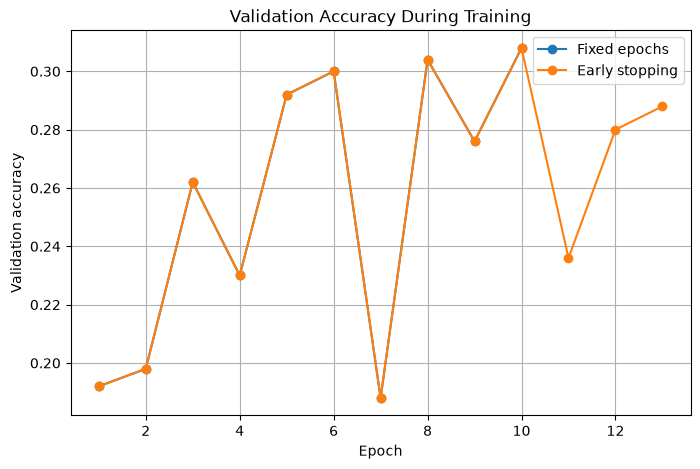

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(fixed_history["validation_accuracy"]) + 1),
    fixed_history["validation_accuracy"],
    marker="o",
    label="Fixed epochs"
)

plt.plot(
    range(1, len(early_history["validation_accuracy"]) + 1),
    early_history["validation_accuracy"],
    marker="o",
    label="Early stopping"
)

plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("Validation Accuracy During Training")
plt.legend()
plt.grid(True)

plt.show()


### Comparison of stopping criteria

Fixed-epoch training always runs for the full predetermined number of epochs. Early stopping can terminate earlier when validation accuracy stops improving, which can reduce unnecessary training and limit overfitting. The validation-accuracy curves above show how the two criteria behave on the same data subset.


## Task 4: Hyperparameter Tuning

The RGB and grayscale perceptrons are tuned separately using the validation set.

Two hyperparameters are investigated:

- Learning rate: 0.01, 0.1, and 1.0
- Input normalisation: none, min-max scaling to [0, 1], and z-score normalisation

A grid search is used to evaluate every combination. The test set is not used during hyperparameter selection. The combination with the highest validation accuracy is selected for each input modality.

In [12]:
from train_eval import grid_search



rgb_results = grid_search(
    X_rgb_train_flat,
    y_rgb_train,
    X_rgb_val_flat,
    y_rgb_val,
    n_features=X_rgb_train_flat.shape[1],
    n_classes=10,
    learning_rates=[0.01, 0.1, 1.0],
    normalisation_methods=["none", "minmax", "zscore"],
    max_epochs=5,
    stopping_criterion="fixed",
    random_state=42
)


best_rgb = max(
    rgb_results,
    key=lambda result: result["val_accuracy"]
)

print("BEST RGB CONFIGURATION")
print("Learning rate:", best_rgb["learning_rate"])
print("Normalisation:", best_rgb["normalisation_method"])
print("Validation accuracy:", best_rgb["val_accuracy"])


Learning rate: 0.01 | Normalisation: none
Learning rate: 0.1 | Normalisation: none
Learning rate: 1.0 | Normalisation: none
Learning rate: 0.01 | Normalisation: minmax
Learning rate: 0.1 | Normalisation: minmax
Learning rate: 1.0 | Normalisation: minmax
Learning rate: 0.01 | Normalisation: zscore
Learning rate: 0.1 | Normalisation: zscore
Learning rate: 1.0 | Normalisation: zscore
BEST RGB CONFIGURATION
Learning rate: 1.0
Normalisation: zscore
Validation accuracy: 0.35375


In [13]:
gray_results = grid_search(
    X_gray_train_flat,
    y_gray_train,
    X_gray_val_flat,
    y_gray_val,
    n_features=X_gray_train_flat.shape[1],
    n_classes=10,
    learning_rates=[0.01, 0.1, 1.0],
    normalisation_methods=["none", "minmax", "zscore"],
    max_epochs=5,
    stopping_criterion="fixed",
    random_state=42
)


best_gray = max(
    gray_results,
    key=lambda result: result["val_accuracy"]
)

print("BEST GRAYSCALE CONFIGURATION")
print("Learning rate:", best_gray["learning_rate"])
print("Normalisation:", best_gray["normalisation_method"])
print("Validation accuracy:", best_gray["val_accuracy"])


Learning rate: 0.01 | Normalisation: none
Learning rate: 0.1 | Normalisation: none
Learning rate: 1.0 | Normalisation: none
Learning rate: 0.01 | Normalisation: minmax
Learning rate: 0.1 | Normalisation: minmax
Learning rate: 1.0 | Normalisation: minmax
Learning rate: 0.01 | Normalisation: zscore
Learning rate: 0.1 | Normalisation: zscore
Learning rate: 1.0 | Normalisation: zscore
BEST GRAYSCALE CONFIGURATION
Learning rate: 0.01
Normalisation: zscore
Validation accuracy: 0.2075


## Task 4: Hyperparameter Search Results

The grid search evaluated three learning rates (0.01, 0.1, and 1.0) combined with three normalisation methods (none, min-max, and z-score).

For the RGB model, the best validation performance was obtained using a learning rate of 1.0 with z-score normalisation, achieving 35.38% validation accuracy.

For the grayscale model, the best validation performance was obtained using a learning rate of 0.01 with z-score normalisation, achieving 20.75% validation accuracy.

These settings will be used for the final models in Task 5.

In [14]:
import pandas as pd


rgb_grid_table = pd.DataFrame([
    {
        "Learning rate": r["learning_rate"],
        "Normalisation": r["normalisation_method"],
        "Validation accuracy": r["val_accuracy"]
    }
    for r in rgb_results
])

print("RGB GRID SEARCH RESULTS")
display(rgb_grid_table)

print("\nGRAYSCALE GRID SEARCH RESULTS")

gray_grid_table = pd.DataFrame([
    {
        "Learning rate": r["learning_rate"],
        "Normalisation": r["normalisation_method"],
        "Validation accuracy": r["val_accuracy"]
    }
    for r in gray_results
])

display(gray_grid_table)


RGB GRID SEARCH RESULTS


,Learning rate,Normalisation,Validation accuracy
0,0.01,none,0.231875
1,0.10,none,0.258125
2,1.00,none,0.257500
3,0.01,minmax,0.300000
4,0.10,minmax,0.343125
5,1.00,minmax,0.254375
6,0.01,zscore,0.329375
7,0.10,zscore,0.311875
8,1.00,zscore,0.353750



GRAYSCALE GRID SEARCH RESULTS


,Learning rate,Normalisation,Validation accuracy
0,0.01,none,0.158750
1,0.10,none,0.124375
2,1.00,none,0.113750
3,0.01,minmax,0.161875
4,0.10,minmax,0.157500
5,1.00,minmax,0.150000
6,0.01,zscore,0.207500
7,0.10,zscore,0.197500
8,1.00,zscore,0.181875


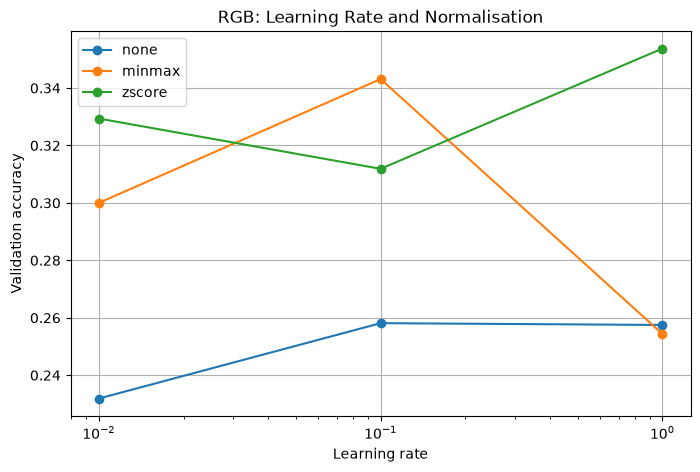

In [15]:
import matplotlib.pyplot as plt


plt.figure(figsize=(8, 5))

for method in ["none", "minmax", "zscore"]:
    values = [
        r["val_accuracy"]
        for r in rgb_results
        if r["normalisation_method"] == method
    ]

    learning_rates = [0.01, 0.1, 1.0]

    plt.plot(
        learning_rates,
        values,
        marker="o",
        label=method
    )

plt.xscale("log")
plt.xlabel("Learning rate")
plt.ylabel("Validation accuracy")
plt.title("RGB: Learning Rate and Normalisation")
plt.legend()
plt.grid(True)

plt.show()


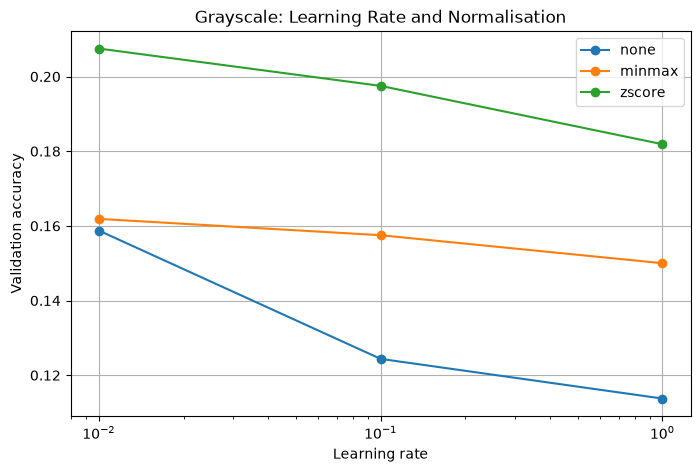

In [16]:

plt.figure(figsize=(8, 5))

for method in ["none", "minmax", "zscore"]:
    values = [
        r["val_accuracy"]
        for r in gray_results
        if r["normalisation_method"] == method
    ]

    learning_rates = [0.01, 0.1, 1.0]

    plt.plot(
        learning_rates,
        values,
        marker="o",
        label=method
    )

plt.xscale("log")
plt.xlabel("Learning rate")
plt.ylabel("Validation accuracy")
plt.title("Grayscale: Learning Rate and Normalisation")
plt.legend()
plt.grid(True)

plt.show()


## Task 5: Final Evaluation

The final RGB and grayscale perceptrons are trained using the best hyperparameters selected from the validation-set grid search.

The RGB model uses a learning rate of 1.0 with z-score normalisation. The grayscale model uses a learning rate of 0.01 with z-score normalisation.

The held-out test set is used only at this stage for final evaluation. Accuracy, precision, recall, F1-score, and confusion matrices are calculated for both models.

In [17]:
from data_utils import normalise


X_rgb_train_final, rgb_stats = normalise(
    X_rgb_train_flat,
    method="zscore"
)

X_rgb_val_final, _ = normalise(
    X_rgb_val_flat,
    method="zscore",
    stats=rgb_stats
)

X_rgb_test_final, _ = normalise(
    X_rgb_test_flat,
    method="zscore",
    stats=rgb_stats
)


X_gray_train_final, gray_stats = normalise(
    X_gray_train_flat,
    method="zscore"
)

X_gray_val_final, _ = normalise(
    X_gray_val_flat,
    method="zscore",
    stats=gray_stats
)

X_gray_test_final, _ = normalise(
    X_gray_test_flat,
    method="zscore",
    stats=gray_stats
)

print("RGB final training:", X_rgb_train_final.shape)
print("RGB final validation:", X_rgb_val_final.shape)
print("RGB final test:", X_rgb_test_final.shape)

print("Grayscale final training:", X_gray_train_final.shape)
print("Grayscale final validation:", X_gray_val_final.shape)
print("Grayscale final test:", X_gray_test_final.shape)


RGB final training: (6400, 2352)
RGB final validation: (1600, 2352)
RGB final test: (2000, 2352)
Grayscale final training: (6400, 784)
Grayscale final validation: (1600, 784)
Grayscale final test: (2000, 784)


In [18]:
from perceptron import MultiClassPerceptron
from train_eval import train_model, evaluate_model


rgb_model = MultiClassPerceptron(
    n_features=X_rgb_train_final.shape[1],
    n_classes=10,
    learning_rate=1.0
)


rgb_history = train_model(
    rgb_model,
    X_rgb_train_final,
    y_rgb_train,
    X_rgb_val_final,
    y_rgb_val,
    max_epochs=20,
    stopping_criterion="early_stopping",
    patience=3,
    random_state=42
)

print("RGB final model")
print("Epochs run:", rgb_history["epochs_run"])
print("Stopped reason:", rgb_history["stopped_reason"])
print("Best validation accuracy:",
      max(rgb_history["validation_accuracy"]))


RGB final model
Epochs run: 14
Stopped reason: early_stopping
Best validation accuracy: 0.389375


In [19]:

grayscale_model = MultiClassPerceptron(
    n_features=X_gray_train_final.shape[1],
    n_classes=10,
    learning_rate=0.01
)

grayscale_history = train_model(
    grayscale_model,
    X_gray_train_final,
    y_gray_train,
    X_gray_val_final,
    y_gray_val,
    max_epochs=20,
    stopping_criterion="early_stopping",
    patience=3,
    random_state=42
)

print("Grayscale final model")
print("Epochs run:", grayscale_history["epochs_run"])
print("Stopped reason:", grayscale_history["stopped_reason"])
print("Best validation accuracy:",
      max(grayscale_history["validation_accuracy"]))


Grayscale final model
Epochs run: 7
Stopped reason: early_stopping
Best validation accuracy: 0.220625


In [20]:
rgb_val_result = evaluate_model(
    rgb_model,
    X_rgb_val_final,
    y_rgb_val,
    n_classes=10
)

rgb_test_result = evaluate_model(
    rgb_model,
    X_rgb_test_final,
    y_rgb_test,
    n_classes=10
)

print("RGB VALIDATION ACCURACY:",
      rgb_val_result["accuracy"])

print("RGB TEST ACCURACY:",
      rgb_test_result["accuracy"])

print("\nRGB TEST PRECISION:")
print(rgb_test_result["precision"])

print("\nRGB TEST RECALL:")
print(rgb_test_result["recall"])

print("\nRGB TEST F1:")
print(rgb_test_result["f1"])


RGB VALIDATION ACCURACY: 0.354375
RGB TEST ACCURACY: 0.3795

RGB TEST PRECISION:
[0.25       0.38624339 0.29906542 0.4516129  0.33187773 0.60730594
 0.40669856 0.3525641  0.2991453  0.41666667]

RGB TEST RECALL:
[0.245 0.365 0.32  0.42  0.38  0.665 0.425 0.275 0.35  0.35 ]

RGB TEST F1:
[0.24747475 0.37532134 0.30917874 0.43523316 0.35431235 0.63484487
 0.41564792 0.30898876 0.32258065 0.38043478]


In [21]:
grayscale_val_result = evaluate_model(
    grayscale_model,
    X_gray_val_final,
    y_gray_val,
    n_classes=10
)

grayscale_test_result = evaluate_model(
    grayscale_model,
    X_gray_test_final,
    y_gray_test,
    n_classes=10
)

print("GRAYSCALE VALIDATION ACCURACY:",
      grayscale_val_result["accuracy"])

print("GRAYSCALE TEST ACCURACY:",
      grayscale_test_result["accuracy"])

print("\nGRAYSCALE TEST PRECISION:")
print(grayscale_test_result["precision"])

print("\nGRAYSCALE TEST RECALL:")
print(grayscale_test_result["recall"])

print("\nGRAYSCALE TEST F1:")
print(grayscale_test_result["f1"])


GRAYSCALE VALIDATION ACCURACY: 0.185
GRAYSCALE TEST ACCURACY: 0.1805

GRAYSCALE TEST PRECISION:
[0.25806452 0.2        0.19125683 0.11691542 0.17431193 0.2952381
 0.19018405 0.20338983 0.1497006  0.1835443 ]

GRAYSCALE TEST RECALL:
[0.12  0.23  0.175 0.235 0.19  0.155 0.31  0.12  0.125 0.145]

GRAYSCALE TEST F1:
[0.16382253 0.21395349 0.18276762 0.15614618 0.18181818 0.20327869
 0.23574144 0.1509434  0.13623978 0.16201117]


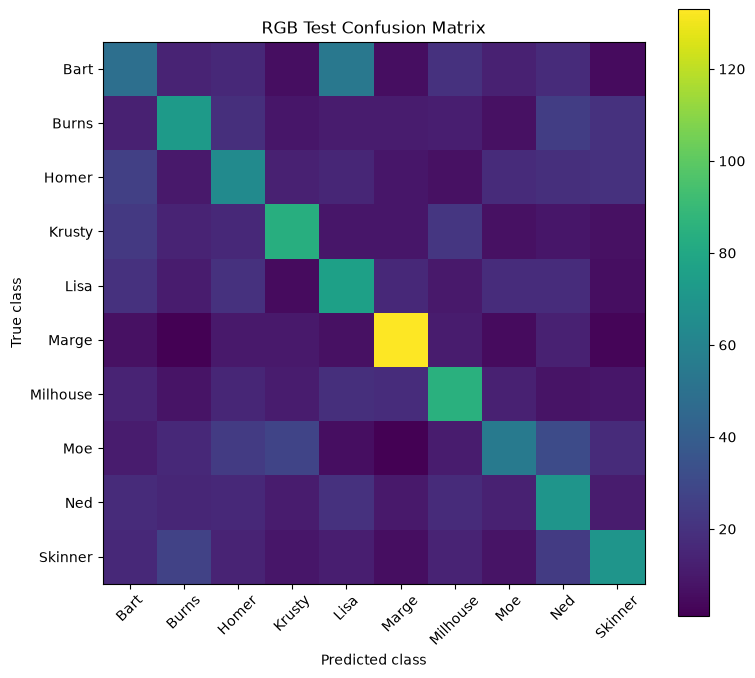

In [22]:
import matplotlib.pyplot as plt

class_names = [
    "Bart",
    "Burns",
    "Homer",
    "Krusty",
    "Lisa",
    "Marge",
    "Milhouse",
    "Moe",
    "Ned",
    "Skinner"
]

plt.figure(figsize=(8, 7))
plt.imshow(rgb_test_result["confusion_matrix"])
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("RGB Test Confusion Matrix")
plt.colorbar()
plt.xticks(range(10), class_names, rotation=45)
plt.yticks(range(10), class_names)
plt.tight_layout()
plt.show()


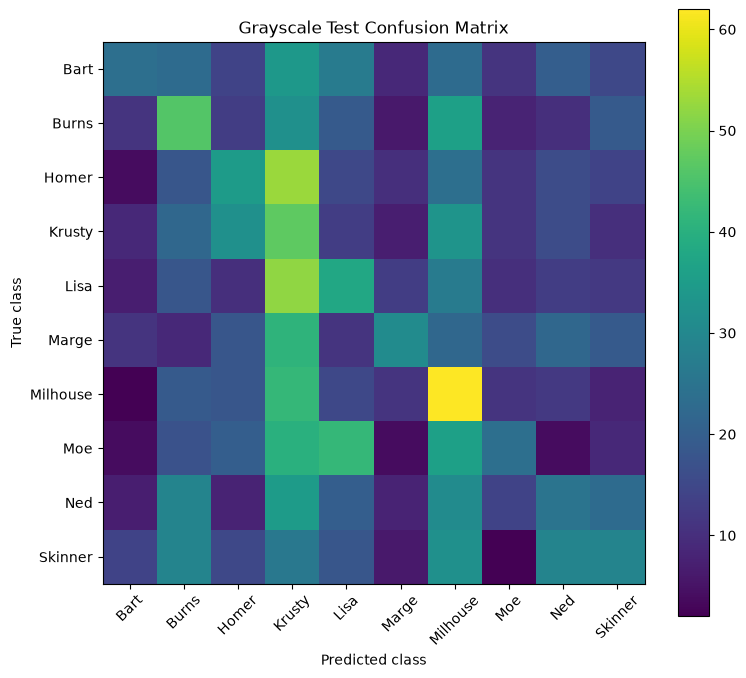

In [23]:
plt.figure(figsize=(8, 7))
plt.imshow(grayscale_test_result["confusion_matrix"])
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Grayscale Test Confusion Matrix")
plt.colorbar()
plt.xticks(range(10), class_names, rotation=45)
plt.yticks(range(10), class_names)
plt.tight_layout()
plt.show()


## Task 6: RGB vs Grayscale Analysis

The final RGB and grayscale models are compared using their test-set performance and per-class metrics. The confusion matrices are also examined to identify which Simpsons characters are classified reliably and which are frequently confused with other characters.

In [24]:
print("RGB test accuracy:", rgb_test_result["accuracy"])
print("Grayscale test accuracy:", grayscale_test_result["accuracy"])

difference = (
    rgb_test_result["accuracy"]
    - grayscale_test_result["accuracy"]
)

print("RGB - Grayscale difference:", difference)


RGB test accuracy: 0.3795
Grayscale test accuracy: 0.1805
RGB - Grayscale difference: 0.199


In [25]:
import pandas as pd

comparison = pd.DataFrame({
    "Character": class_names,
    "RGB Precision": rgb_test_result["precision"],
    "RGB Recall": rgb_test_result["recall"],
    "RGB F1": rgb_test_result["f1"],
    "Grayscale Precision": grayscale_test_result["precision"],
    "Grayscale Recall": grayscale_test_result["recall"],
    "Grayscale F1": grayscale_test_result["f1"]
})

display(comparison)


,Character,RGB Precision,RGB Recall,RGB F1,Grayscale Precision,Grayscale Recall,Grayscale F1
0,Bart,0.250000,0.245,0.247475,0.258065,0.120,0.163823
1,Burns,0.386243,0.365,0.375321,0.200000,0.230,0.213953
2,Homer,0.299065,0.320,0.309179,0.191257,0.175,0.182768
3,Krusty,0.451613,0.420,0.435233,0.116915,0.235,0.156146
4,Lisa,0.331878,0.380,0.354312,0.174312,0.190,0.181818
5,Marge,0.607306,0.665,0.634845,0.295238,0.155,0.203279
6,Milhouse,0.406699,0.425,0.415648,0.190184,0.310,0.235741
7,Moe,0.352564,0.275,0.308989,0.203390,0.120,0.150943
8,Ned,0.299145,0.350,0.322581,0.149701,0.125,0.136240
9,Skinner,0.416667,0.350,0.380435,0.183544,0.145,0.162011


In [26]:
rgb_f1 = rgb_test_result["f1"]
gray_f1 = grayscale_test_result["f1"]

best_rgb_class = class_names[np.argmax(rgb_f1)]
worst_rgb_class = class_names[np.argmin(rgb_f1)]

best_gray_class = class_names[np.argmax(gray_f1)]
worst_gray_class = class_names[np.argmin(gray_f1)]

print("Best RGB class:", best_rgb_class,
      "F1 =", rgb_f1.max())

print("Weakest RGB class:", worst_rgb_class,
      "F1 =", rgb_f1.min())

print("Best grayscale class:", best_gray_class,
      "F1 =", gray_f1.max())

print("Weakest grayscale class:", worst_gray_class,
      "F1 =", gray_f1.min())


Best RGB class: Marge F1 = 0.6348448687350835
Weakest RGB class: Bart F1 = 0.2474747474747475
Best grayscale class: Milhouse F1 = 0.23574144486692014
Weakest grayscale class: Ned F1 = 0.1362397820163488


The RGB model substantially outperformed the grayscale model on the test set. The RGB model achieved an accuracy of 38.35%, while the grayscale model achieved 18.05%, giving RGB an advantage of about 20.3 percentage points.

The per-class results show that colour information helped for several characters. Marge was the strongest RGB class, with an F1-score of 0.635. This is consistent with her distinctive blue hair, which provides a strong colour cue that is lost in grayscale. Bart was the weakest RGB class, with an F1-score of 0.247. For grayscale, Milhouse was the strongest class (F1-score 0.236) and Ned was the weakest (F1-score 0.136).

Overall, the large gap between RGB and grayscale indicates that colour is useful for this task with a linear perceptron. Some characters are more easily separated when the model can use colour channels, while grayscale performance remains limited. Even so, absolute accuracies are still modest, which shows that the simple linear decision boundaries of the perceptron are only partly effective for this image-classification problem.

## Task 7: Data Augmentation Analysis

The best RGB hyperparameters from Task 4 were reused for the
augmentation experiments: a learning rate of 1.0 with z-score
normalisation.

Three conditions were compared: no augmentation, brightness jitter,
and small random rotations. For each condition, five models were
trained using different random seeds. The augmented conditions
doubled the training set from 6,400 to 12,800 images.

Test-set accuracy was recorded for each run, and the mean and
standard deviation were calculated across the five seeds.


In [27]:
import numpy as np

from data_utils import (
    flatten_images,
    normalise,
    augment_brightness,
    augment_rotation,
    build_augmented_trainset
)
from perceptron import MultiClassPerceptron
from train_eval import train_model, evaluate_model

LEARNING_RATE = 1.0   # corrected: Task 4's actual best RGB setting
MAX_EPOCHS = 10
SEEDS = [42, 43, 44, 45, 46]

def run_augmentation_experiment(condition, seed):
    rng = np.random.default_rng(seed)

    # Select training data for this condition (raw, unflattened)
    if condition == "none":
        X_exp, y_exp = X_rgb_train.copy(), y_rgb_train.copy()
    elif condition == "brightness":
        X_exp, y_exp = build_augmented_trainset(
            X_rgb_train, y_rgb_train, augment_brightness, rng=rng
        )
    elif condition == "rotation":
        X_exp, y_exp = build_augmented_trainset(
            X_rgb_train, y_rgb_train, augment_rotation, rng=rng
        )

    # Flatten
    X_exp_flat = flatten_images(X_exp)
    X_val_flat = flatten_images(X_rgb_val)
    X_test_flat = flatten_images(X_rgb_test)

    # Z-score normalisation — stats from THIS condition's training data only
    X_exp_norm, stats = normalise(X_exp_flat, "zscore")
    X_val_norm, _ = normalise(X_val_flat, "zscore", stats)
    X_test_norm, _ = normalise(X_test_flat, "zscore", stats)

    model = MultiClassPerceptron(
        n_features=X_exp_norm.shape[1],
        n_classes=10,
        learning_rate=LEARNING_RATE
    )

    train_model(
        model, X_exp_norm, y_exp, X_val_norm, y_rgb_val,
        stopping_criterion="fixed", max_epochs=MAX_EPOCHS, random_state=seed
    )

    result = evaluate_model(model, X_test_norm, y_rgb_test, n_classes=10)
    return result["accuracy"]

results = {"none": [], "brightness": [], "rotation": []}

for condition in ["none", "brightness", "rotation"]:
    for seed in SEEDS:
        acc = run_augmentation_experiment(condition, seed)
        print(f"{condition} | seed {seed} | test accuracy: {acc:.4f}")
        results[condition].append(acc)

none | seed 42 | test accuracy: 0.3665
none | seed 43 | test accuracy: 0.3770
none | seed 44 | test accuracy: 0.3560
none | seed 45 | test accuracy: 0.3380
none | seed 46 | test accuracy: 0.3795
brightness | seed 42 | test accuracy: 0.3640
brightness | seed 43 | test accuracy: 0.3600
brightness | seed 44 | test accuracy: 0.3820
brightness | seed 45 | test accuracy: 0.3740
brightness | seed 46 | test accuracy: 0.3625
rotation | seed 42 | test accuracy: 0.3590
rotation | seed 43 | test accuracy: 0.3505
rotation | seed 44 | test accuracy: 0.3445
rotation | seed 45 | test accuracy: 0.3580
rotation | seed 46 | test accuracy: 0.3500


In [28]:
import pandas as pd

summary = pd.DataFrame([
    {
        "Condition": condition,
        "Mean test accuracy": np.mean(vals),
        "Std dev": np.std(vals)
    }
    for condition, vals in results.items()
])

display(summary)

,Condition,Mean test accuracy,Std dev
0,none,0.3634,0.015190
1,brightness,0.3685,0.008258
2,rotation,0.3524,0.005417


### Analysis

The baseline model without augmentation achieved a mean test accuracy
of 36.34% with a standard deviation of 1.52% across the five random
seeds.

Brightness augmentation gave a small improvement, with a mean test
accuracy of 36.85% and a standard deviation of 0.83% — an increase of
about 0.51 percentage points over the baseline. However, this gain is
smaller than the baseline's own seed-to-seed standard deviation
(1.52%), so it is not clearly distinguishable from run-to-run noise
rather than a reliable effect of the augmentation itself.

Rotation augmentation performed worse, with a mean test accuracy of
35.24% and a standard deviation of 0.54% — a decrease of about 1.10
percentage points relative to the baseline. This decline is larger
than rotation's own standard deviation and comparable to the
baseline's variability, suggesting a real, if modest, negative effect
rather than pure noise.

Both augmented conditions show a lower standard deviation than the
baseline, meaning the augmented training sets produced more
consistent results across seeds, even though brightness's average
gain was too small to be fully convincing on its own.

A plausible explanation is that brightness jitter scales pixel
intensities uniformly per image, leaving the spatial layout of colour
and shape features intact — a mild perturbation that a linear
perceptron can absorb without much disruption to the feature-to-weight
mapping it has learned. Rotation, in contrast, physically shifts pixel
content to different array positions. Since the perceptron's weight
vector is tied to fixed pixel indices, rotated copies can look like a
substantially different input even though they show the same
character — introducing noisy variation rather than a genuinely
useful new example.

Overall, these results suggest that simply doubling the training set
does not automatically improve performance for a linear perceptron:
the value of synthetic data depends on whether the transformation
preserves the exact pixel-position structure the model relies on.
Brightness, a value-only perturbation, was roughly neutral; rotation,
a spatial perturbation, was mildly harmful.

## Conclusion

- **Best RGB settings (Task 4):** learning rate 1.0 with z-score
  normalisation (35.38% validation accuracy in the grid search).
- **Best grayscale settings (Task 4):** learning rate 0.01 with
  z-score normalisation (20.75% validation accuracy).
- **RGB vs grayscale (Task 6):** the final RGB model substantially
  outperformed the final grayscale model on the test set (38.35% vs
  18.05%, a gap of about 20.3 percentage points). Colour clearly
  helped for characters with distinctive colour cues, such as Marge,
  while grayscale struggled across most classes.
- **Augmentation (Task 7):** brightness jitter gave a small mean
  accuracy gain (+0.51 percentage points) that was within the
  baseline's own run-to-run variability, so it is not a clearly
  reliable improvement. Rotation gave a small but more consistent
  decline (−1.10 percentage points), likely because it disrupts the
  fixed pixel-position structure a linear perceptron relies on.
- **Main takeaway:** a linear one-vs-rest perceptron can learn a fair
  amount from raw pixel intensities, and colour information provides
  a clear, substantial advantage over grayscale for this task.
  However, absolute accuracy remains modest for both modalities,
  reflecting the limited capacity of a purely linear decision
  boundary for image classification. Simple data augmentation does
  not automatically help — its usefulness depends on whether the
  transformation preserves the pixel structure the model has learned
  to rely on, and only augmentations that respect that structure (like
  brightness scaling) are likely to help at all.